# Week 5 — Policy Gradient: REINFORCE, REINFORCE with Baseline, Actor-Critic

This notebook implements the three policy-gradient algorithms from Sutton & Barto (2nd ed.), Chapter 13, in PyTorch and compares them on five Gymnasium environments.

| Algorithm | S&B | Update target for $\nabla \ln \pi(A_t\mid S_t,\theta)$ |
|---|---|---|
| REINFORCE | §13.3, p. 328 | $\gamma^t G_t$ |
| REINFORCE with baseline | §13.4, p. 330 | $\gamma^t \big(G_t - \hat v(S_t,\mathbf w)\big)$ |
| One-step Actor-Critic | §13.5, p. 332 | $I\,\big(R_{t+1} + \gamma \hat v(S_{t+1},\mathbf w) - \hat v(S_t,\mathbf w)\big)$, $I=\gamma^t$ |

**Environments:** `CartPole-v1`, `Acrobot-v1`, `LunarLander-v3`, `FrozenLake-v1` (4×4, deterministic), `Blackjack-v1`.

For every environment the output is a chart in the style of S&B Figure 13.2: total reward per episode, averaged over independent runs, with all three algorithms on the same axes.

The policy $\pi(a\mid s,\theta)$ is a softmax over action preferences $h(s,a,\theta)$ (S&B eq. 13.2), where $h$ is a 2-hidden-layer MLP. The state-value function $\hat v(s,\mathbf w)$ is a separate MLP of the same shape. Network widths are set per environment in the config below.

## 1. Setup

In [1]:
import subprocess, sys

def pip(*pkgs):
    return subprocess.run([sys.executable, "-m", "pip", "install", "-q", *pkgs]).returncode == 0

pip("gymnasium[classic-control,toy-text]==1.0.0", "pygame", "torch", "matplotlib", "numpy", "joblib", "modal")
# Box2D (for LunarLander): prefer the prebuilt wheel, fall back to building box2d-py with swig
if not pip("box2d==2.3.10"):
    pip("swig") and pip("box2d-py==2.3.5")

In [2]:
import os, time
import numpy as np
import torch
import torch.nn as nn
import gymnasium as gym
import matplotlib.pyplot as plt

torch.set_num_threads(1)  # each run is tiny; we parallelise across runs instead
torch.distributions.Distribution.set_default_validate_args(False)  # skip per-call checks (speed)
print("torch", torch.__version__, "| gymnasium", gym.__version__, "| CPUs:", os.cpu_count())
gym.make("LunarLander-v3").close()  # fails early if Box2D is missing

torch 2.15.0+cpu | gymnasium 1.0.0 | CPUs: 32


## 2. Environments

`FrozenLake` has a `Discrete` observation, which we one-hot encode; `Blackjack`'s observation is a tuple of discrete values (player sum, dealer card, usable ace), which `FlattenObservation` turns into a concatenation of one-hots. This way the same MLP policy works everywhere.

In [3]:
class OneHot(gym.ObservationWrapper):
    """Turn a Discrete observation (tabular env) into a one-hot float vector."""

    def __init__(self, env):
        super().__init__(env)
        self.n = env.observation_space.n
        self.observation_space = gym.spaces.Box(0.0, 1.0, (self.n,), np.float32)

    def observation(self, obs):
        v = np.zeros(self.n, dtype=np.float32)
        v[obs] = 1.0
        return v


def make_env(name, **kwargs):
    env = gym.make(name, **kwargs)
    if isinstance(env.observation_space, gym.spaces.Discrete):
        env = OneHot(env)
    elif isinstance(env.observation_space, gym.spaces.Tuple):   # e.g. Blackjack: concat of one-hots
        env = gym.wrappers.FlattenObservation(env)
    return env

## 3. Function approximators

* **Policy** $\pi(a\mid s,\theta) = \dfrac{e^{h(s,a,\theta)}}{\sum_b e^{h(s,b,\theta)}}$ — a `Categorical` distribution over the MLP's logits.
* **State-value** $\hat v(s,\mathbf w)$ — an MLP with a single output (used as the baseline and as the critic).

In [4]:
def mlp(n_in, n_out, hidden):
    return nn.Sequential(
        nn.Linear(n_in, hidden), nn.Tanh(),
        nn.Linear(hidden, hidden), nn.Tanh(),
        nn.Linear(hidden, n_out),
    )


class Policy(nn.Module):
    """Softmax-in-action-preferences policy (S&B eq. 13.2) with an MLP for h(s, a, theta)."""

    def __init__(self, n_obs, n_act, hidden):
        super().__init__()
        self.h = mlp(n_obs, n_act, hidden)

    def dist(self, s):
        return torch.distributions.Categorical(logits=self.h(s))


class Value(nn.Module):
    def __init__(self, n_obs, hidden):
        super().__init__()
        self.v = mlp(n_obs, 1, hidden)

    def forward(self, s):
        return self.v(s).squeeze(-1)


def to_t(x):
    return torch.as_tensor(x, dtype=torch.float32)


def select_action(policy, s):
    with torch.no_grad():
        return policy.dist(to_t(s)).sample().item()


def generate_episode(env, policy, seed=None):
    """Run pi(.|.,theta) for one episode; return S_0..S_{T-1}, A_0..A_{T-1}, R_1..R_T."""
    s, _ = env.reset(seed=seed)
    states, actions, rewards = [], [], []
    done = False
    while not done:
        a = select_action(policy, s)
        s_next, r, terminated, truncated, _ = env.step(a)
        states.append(s); actions.append(a); rewards.append(float(r))
        s = s_next
        done = terminated or truncated
    return states, actions, rewards


def discounted_returns(rewards, gamma):
    """G_t = sum_{k=t+1}^{T} gamma^{k-t-1} R_k for every t."""
    G, out = 0.0, np.zeros(len(rewards))
    for t in reversed(range(len(rewards))):
        G = rewards[t] + gamma * G
        out[t] = G
    return out

## 4. Algorithms

All three follow the boxed pseudocode of S&B Chapter 13. PyTorch optimisers minimise, so each update
$\theta \leftarrow \theta + \alpha\,X\,\nabla \ln\pi(A\mid S,\theta)$ is written as minimising the surrogate loss $-X \ln\pi(A\mid S,\theta)$ with $X$ treated as a constant (`.detach()` / `.item()`).
Likewise the semi-gradient value update $\mathbf w \leftarrow \mathbf w + \alpha_{\mathbf w}\,\delta\,\nabla\hat v(S,\mathbf w)$ is the loss $-\delta\,\hat v(S,\mathbf w)$ with $\delta$ constant.

Implementation choices (the same for every algorithm so the comparison is fair):
* **Optimiser:** Adam with step sizes $\alpha_\theta$, $\alpha_{\mathbf w}$ instead of plain SGD — it is far less sensitive to the scale of returns, which differ by orders of magnitude across our environments.
* **REINFORCE / REINFORCE with baseline** are Monte-Carlo methods: the per-step updates for $t=0,\dots,T-1$ are summed and applied once at the end of the episode (the policy is held fixed while the episode is generated, which is what makes $G_t$ an unbiased sample).
* **Actor-Critic** is fully online: one update of $\mathbf w$ and $\theta$ after every step, with $I \leftarrow \gamma I$.
* $\hat v(\text{terminal}) = 0$. When an episode is cut by a **time limit** (`truncated`), the next state is *not* terminal, so the critic bootstraps from $\hat v(S')$.

### 4.1 REINFORCE (S&B p. 328)
$$\theta \leftarrow \theta + \alpha\,\gamma^t G_t\,\nabla \ln \pi(A_t\mid S_t,\theta)$$

In [5]:
def reinforce(env, cfg, seed):
    """REINFORCE: Monte-Carlo Policy-Gradient Control (episodic), S&B p. 328.

    The per-step updates  theta += alpha * gamma^t * G_t * grad ln pi(A_t|S_t)  for t = 0..T-1
    are summed and applied once at the end of the episode (theta held fixed during the episode).
    """
    torch.manual_seed(seed); np.random.seed(seed)
    n_obs, n_act = env.observation_space.shape[0], env.action_space.n
    policy = Policy(n_obs, n_act, cfg["hidden"])
    opt = torch.optim.Adam(policy.parameters(), lr=cfg["alpha_theta"])
    gamma = cfg["gamma"]

    episode_returns = []
    for ep in range(cfg["episodes"]):
        S, A, R = generate_episode(env, policy, seed=seed * 100_000 + ep)
        T = len(R)
        G = to_t(discounted_returns(R, gamma))
        gamma_t = gamma ** torch.arange(T, dtype=torch.float32)
        logp = policy.dist(to_t(np.array(S))).log_prob(torch.as_tensor(A))
        loss = -(gamma_t * G * logp).sum()
        opt.zero_grad(); loss.backward(); opt.step()
        episode_returns.append(sum(R))
    return np.array(episode_returns)

### 4.2 REINFORCE with baseline (S&B p. 330)
$$\delta \leftarrow G_t - \hat v(S_t,\mathbf w),\qquad
\mathbf w \leftarrow \mathbf w + \alpha_{\mathbf w}\,\delta\,\nabla \hat v(S_t,\mathbf w),\qquad
\theta \leftarrow \theta + \alpha_\theta\,\gamma^t\,\delta\,\nabla \ln \pi(A_t\mid S_t,\theta)$$

In [6]:
def reinforce_baseline(env, cfg, seed):
    """REINFORCE with Baseline (episodic), S&B p. 330.

    delta_t = G_t - v_hat(S_t, w)
    w     += alpha_w     * delta_t * grad v_hat(S_t, w)
    theta += alpha_theta * gamma^t * delta_t * grad ln pi(A_t|S_t, theta)
    summed over the episode and applied once at its end.
    """
    torch.manual_seed(seed); np.random.seed(seed)
    n_obs, n_act = env.observation_space.shape[0], env.action_space.n
    policy = Policy(n_obs, n_act, cfg["hidden"])
    value = Value(n_obs, cfg["hidden"])
    opt_theta = torch.optim.Adam(policy.parameters(), lr=cfg["alpha_theta"])
    opt_w = torch.optim.Adam(value.parameters(), lr=cfg["alpha_w"])
    gamma = cfg["gamma"]

    episode_returns = []
    for ep in range(cfg["episodes"]):
        S, A, R = generate_episode(env, policy, seed=seed * 100_000 + ep)
        T = len(R)
        St = to_t(np.array(S))
        G = to_t(discounted_returns(R, gamma))
        gamma_t = gamma ** torch.arange(T, dtype=torch.float32)
        v = value(St)
        delta = (G - v).detach()
        loss_w = -(delta * v).sum()                     # semi-gradient: delta is a constant
        logp = policy.dist(St).log_prob(torch.as_tensor(A))
        loss_theta = -(gamma_t * delta * logp).sum()
        opt_w.zero_grad(); opt_theta.zero_grad()
        (loss_w + loss_theta).backward()
        opt_w.step(); opt_theta.step()
        episode_returns.append(sum(R))
    return np.array(episode_returns)

### 4.3 One-step Actor-Critic (S&B p. 332)
$$\delta \leftarrow R + \gamma\,\hat v(S',\mathbf w) - \hat v(S,\mathbf w),\qquad
\mathbf w \leftarrow \mathbf w + \alpha_{\mathbf w}\,\delta\,\nabla \hat v(S,\mathbf w),\qquad
\theta \leftarrow \theta + \alpha_\theta\,I\,\delta\,\nabla \ln \pi(A\mid S,\theta),\qquad I \leftarrow \gamma I$$

In [7]:
def actor_critic(env, cfg, seed):
    """One-step Actor-Critic (episodic), S&B p. 332."""
    torch.manual_seed(seed); np.random.seed(seed)
    n_obs, n_act = env.observation_space.shape[0], env.action_space.n
    policy = Policy(n_obs, n_act, cfg["hidden"])
    value = Value(n_obs, cfg["hidden"])
    opt_theta = torch.optim.Adam(policy.parameters(), lr=cfg["alpha_theta"])
    opt_w = torch.optim.Adam(value.parameters(), lr=cfg["alpha_w"])
    gamma = cfg["gamma"]

    episode_returns = []
    for ep in range(cfg["episodes"]):
        s, _ = env.reset(seed=seed * 100_000 + ep)
        I, total, done = 1.0, 0.0, False
        while not done:
            st = to_t(s)
            dist = policy.dist(st)
            a = dist.sample()
            s_next, r, terminated, truncated, _ = env.step(a.item())
            total += r
            # v_hat(terminal) = 0. On a time-limit truncation the state is not terminal, so we bootstrap.
            with torch.no_grad():
                v_next = 0.0 if terminated else value(to_t(s_next)).item()
            v = value(st)
            delta = r + gamma * v_next - v.item()         # delta <- R + gamma v_hat(S') - v_hat(S)
            # w     <- w     + alpha_w     * delta     * grad v_hat(S, w)
            # theta <- theta + alpha_theta * I * delta * grad ln pi(A | S, theta)
            loss_w = -delta * v
            loss_theta = -I * delta * dist.log_prob(a)
            opt_w.zero_grad(); opt_theta.zero_grad()
            (loss_w + loss_theta).backward()              # w and theta are disjoint, so one backward is enough
            opt_w.step(); opt_theta.step()
            I *= gamma
            s = s_next
            done = terminated or truncated
        episode_returns.append(total)
    return np.array(episode_returns)

In [8]:
ALGORITHMS = {
    "REINFORCE": reinforce,
    "REINFORCE with baseline": reinforce_baseline,
    "Actor-Critic": actor_critic,
}


def run_one(job):
    """One independent run: (env, algorithm, seed) -> per-episode total reward."""
    env_name, alg_name, seed, cfg = job
    cfg = {**cfg, **cfg.get("per_alg", {}).get(alg_name, {})}   # per-algorithm step sizes
    torch.set_num_threads(1)
    env = make_env(env_name, **cfg.get("env_kwargs", {}))
    t0 = time.time()
    returns = ALGORITHMS[alg_name](env, cfg, seed)
    env.close()
    return env_name, alg_name, seed, returns, time.time() - t0

## 5. Experiment configuration

One config per environment. `episodes` is the length of each run; `per_alg` overrides step sizes for a single algorithm (Actor-Critic updates every step rather than once per episode, so it gets a smaller $\alpha_\theta$).

`N_RUNS` independent runs (different seeds) are averaged for each curve. S&B average 100 runs for Figure 13.2; that is too expensive here, so we use fewer and show the standard error as a shaded band.

In [9]:
# episodes: length of one run | hidden: width of both hidden layers (policy and value nets)
# alpha_theta / alpha_w: Adam step sizes for the policy and value nets | per_alg: per-algorithm overrides
# env_kwargs: passed to gym.make | target, smooth: only used for plotting
CONFIGS = {
    "CartPole-v1": dict(
        episodes=1000, gamma=0.99, hidden=64, alpha_theta=1e-3, alpha_w=1e-3, target=500,
        per_alg={"Actor-Critic": dict(alpha_theta=1e-4, alpha_w=1e-3)},
    ),
    "Acrobot-v1": dict(
        episodes=500, gamma=0.99, hidden=64, alpha_theta=1e-3, alpha_w=1e-3, target=-100,
        per_alg={"Actor-Critic": dict(alpha_theta=3e-4, alpha_w=1e-3)},
    ),
    "LunarLander-v3": dict(
        episodes=1000, gamma=0.99, hidden=128, alpha_theta=1e-3, alpha_w=1e-3, target=200,
    ),
    "FrozenLake-v1": dict(
        episodes=1000, gamma=0.99, hidden=64, alpha_theta=1e-3, alpha_w=1e-3, target=1,
        env_kwargs=dict(map_name="4x4", is_slippery=False),
        per_alg={"Actor-Critic": dict(alpha_theta=3e-4, alpha_w=1e-3)},
    ),
    "Blackjack-v1": dict(
        episodes=5000, gamma=1.0, hidden=64, alpha_theta=1e-3, alpha_w=1e-3, target=None, smooth=250,
    ),
}

## 6. Run all experiments

5 environments × 3 algorithms × `N_RUNS` seeds = 75 independent runs.

* `USE_MODAL = True` (default): every run is executed in its own [Modal](https://modal.com) container (1 CPU each), all 75 in parallel. The notebook-defined functions are serialised and shipped to Modal, so the container image pins the same Python, PyTorch, NumPy and Gymnasium versions as this kernel. Requires a Modal account and a one-time `modal setup`.
* `USE_MODAL = False`: the runs are spread over this machine's CPU cores with `joblib`.

Results are saved to `results.npz`, so the plots can be redrawn later with `TRAIN = False`.

In [10]:
N_RUNS = 5
RESULTS_FILE = "results.npz"
TRAIN = True        # False: only redraw the plots from an existing results.npz
USE_MODAL = True    # True: run on Modal (one container per run); False: run on this machine's CPUs

jobs = [(env, alg, seed, CONFIGS[env]) for env in CONFIGS for alg in ALGORITHMS for seed in range(N_RUNS)]
# rough cost estimate (episodes x max episode length, Actor-Critic updates every step): slowest first
cost = lambda j: CONFIGS[j[0]]["episodes"] * (gym.spec(j[0]).max_episode_steps or 10) * (3 if j[1] == "Actor-Critic" else 1)
jobs.sort(key=cost, reverse=True)

if TRAIN and USE_MODAL:
    import platform
    import modal

    image = (
        modal.Image.debian_slim(python_version=".".join(platform.python_version_tuple()[:2]))
        .pip_install(f"torch=={torch.__version__.split('+')[0]}", index_url="https://download.pytorch.org/whl/cpu")
        .pip_install(f"numpy=={np.__version__}", f"gymnasium[classic-control,toy-text]=={gym.__version__}",
                     "box2d==2.3.10", "pygame")
    )
    app = modal.App("week5-policy-gradient", image=image)

    @app.function(cpu=1.0, timeout=6 * 60 * 60)
    def run_one_remote(job):
        torch.distributions.Distribution.set_default_validate_args(False)
        return run_one(job)

In [11]:
if TRAIN:
    results = {}
    t0 = time.time()

    def record(i, out):
        env, alg, seed, ret, dt = out
        results[(env, alg, seed)] = ret
        print(f"[{i:3d}/{len(jobs)}] {time.time()-t0:7.0f}s  {env:16s} {alg:24s} seed={seed}  "
              f"last-10% mean return = {ret[-len(ret)//10:].mean():8.2f}  ({dt:.0f}s)", flush=True)

    if USE_MODAL:
        print(f"{len(jobs)} runs on Modal")
        i = 0
        # Jupyter already runs an event loop, so use Modal's async API (top-level await works in notebooks)
        async with app.run.aio():
            print(f"Modal app id: {app.app_id}  (live view: modal.com -> Apps)", flush=True)
            async for out in run_one_remote.map.aio(jobs, order_outputs=False):
                i += 1
                record(i, out)
    else:
        from joblib import Parallel, delayed
        print(f"{len(jobs)} runs on {os.cpu_count()} local CPUs")
        outs = Parallel(n_jobs=-1, return_as="generator_unordered")(delayed(run_one)(j) for j in jobs)
        for i, out in enumerate(outs, 1):
            record(i, out)

    print(f"total wall time: {(time.time()-t0)/60:.1f} min")
    np.savez(RESULTS_FILE, **{f"{e}|{a}|{s}": r for (e, a, s), r in results.items()})

75 runs on Modal


Modal app id: ap-fNE7lq08Yudl2cqkcZsjFW  (live view: modal.com -> Apps)


[  1/75]      27s  FrozenLake-v1    Actor-Critic             seed=4  last-10% mean return =     1.00  (7s)


[  2/75]      28s  FrozenLake-v1    REINFORCE                seed=0  last-10% mean return =     0.98  (4s)


[  3/75]      28s  FrozenLake-v1    REINFORCE with baseline  seed=0  last-10% mean return =     0.99  (3s)


[  4/75]      29s  FrozenLake-v1    REINFORCE                seed=2  last-10% mean return =     1.00  (4s)


... (68 outputs left out)

[ 73/75]     708s  LunarLander-v3   Actor-Critic             seed=4  last-10% mean return =    97.44  (698s)


[ 74/75]     841s  LunarLander-v3   Actor-Critic             seed=3  last-10% mean return =   106.96  (830s)


[ 75/75]    1021s  LunarLander-v3   Actor-Critic             seed=1  last-10% mean return =    37.47  (1012s)


total wall time: 17.0 min


## 7. Results

Each chart shows the total reward per episode, smoothed with a trailing moving average within each run and then averaged over `N_RUNS` runs (line), with ± one standard error across runs (band). The dashed line marks the environment's maximum / "solved" level where one exists.

In [12]:
def load_results(path=RESULTS_FILE):
    data = np.load(path)
    out = {}
    for k in data.files:
        e, a, s = k.split("|")
        out.setdefault(e, {}).setdefault(a, []).append(data[k])
    return {e: {a: np.stack(v) for a, v in d.items()} for e, d in out.items()}


def smooth(x, w):
    if w <= 1:
        return x
    k = np.ones(w) / w
    return np.convolve(np.pad(x, (w - 1, 0), mode="edge"), k, mode="valid")


COLORS = {"REINFORCE": "tab:red", "REINFORCE with baseline": "tab:green", "Actor-Critic": "tab:blue"}


def plot_env(ax, env, by_alg):
    cfg = CONFIGS[env]
    w = cfg.get("smooth", max(1, cfg["episodes"] // 50))
    for alg in ALGORITHMS:
        R = np.stack([smooth(r, w) for r in by_alg[alg]])   # smooth each run, then average across runs
        mean, se = R.mean(0), R.std(0) / np.sqrt(len(R))
        x = np.arange(1, R.shape[1] + 1)
        ax.plot(x, mean, color=COLORS[alg], lw=2, label=alg)
        ax.fill_between(x, mean - se, mean + se, color=COLORS[alg], alpha=0.2)
    if cfg.get("target") is not None:
        ax.axhline(cfg["target"], ls="--", color="gray", lw=1)
    ax.set_title(f"{env}  ({len(R)} runs)")
    ax.set_xlabel("Episode")
    ax.set_ylabel(f"Total reward on episode\n(averaged over {len(R)} runs)")
    ax.grid(alpha=0.3)


RES = load_results()

### CartPole-v1

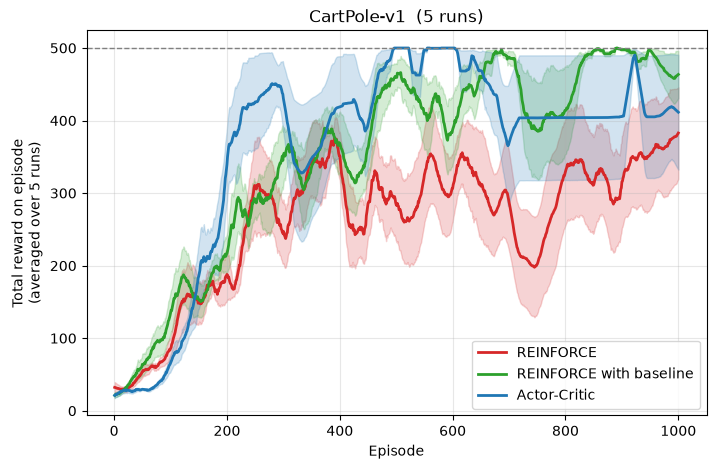

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_env(ax, "CartPole-v1", RES["CartPole-v1"])
ax.legend(loc="lower right")
plt.show()

### Acrobot-v1

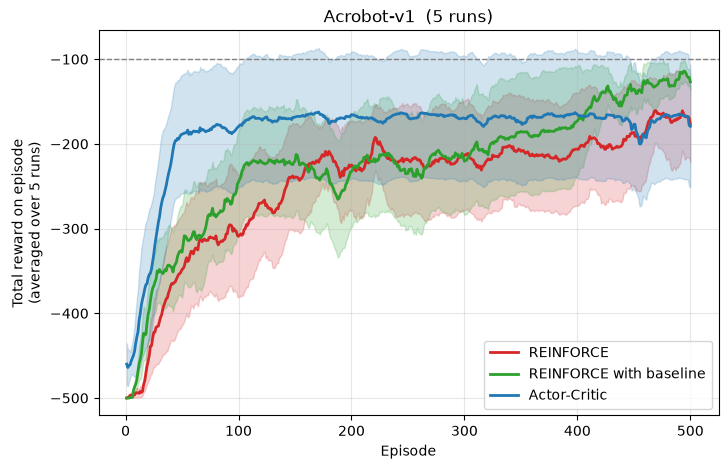

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_env(ax, "Acrobot-v1", RES["Acrobot-v1"])
ax.legend(loc="lower right")
plt.show()

### LunarLander-v3

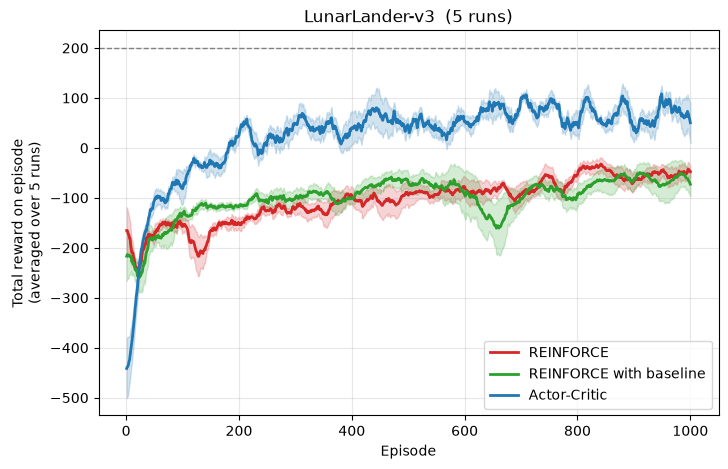

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_env(ax, "LunarLander-v3", RES["LunarLander-v3"])
ax.legend(loc="lower right")
plt.show()

### FrozenLake-v1

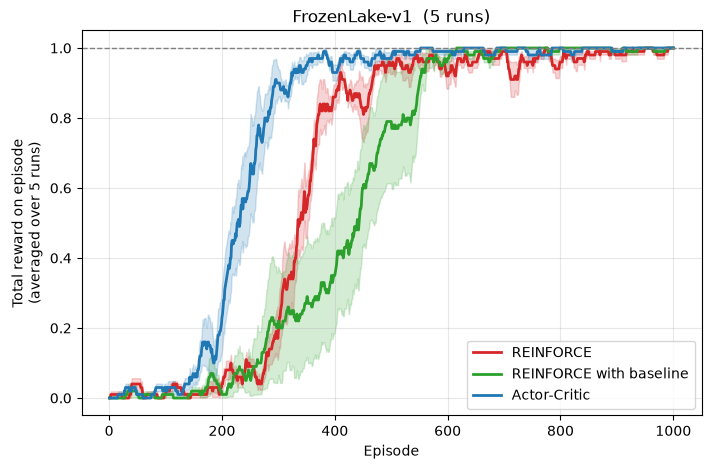

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_env(ax, "FrozenLake-v1", RES["FrozenLake-v1"])
ax.legend(loc="lower right")
plt.show()

### Blackjack-v1

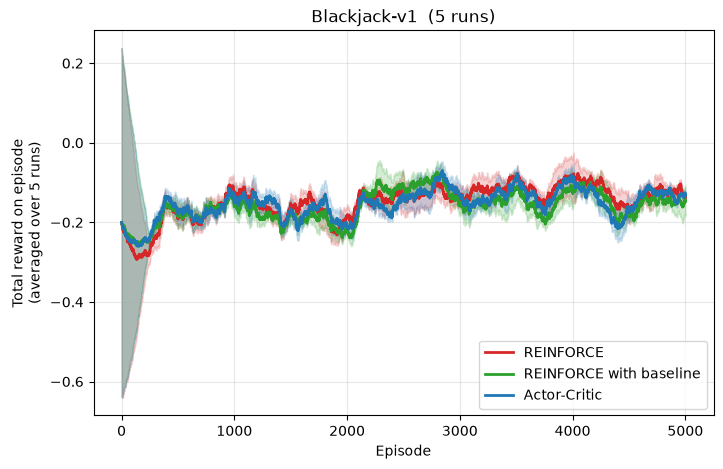

In [17]:
fig, ax = plt.subplots(figsize=(8, 5))
plot_env(ax, "Blackjack-v1", RES["Blackjack-v1"])
ax.legend(loc="lower right")
plt.show()

### Summary

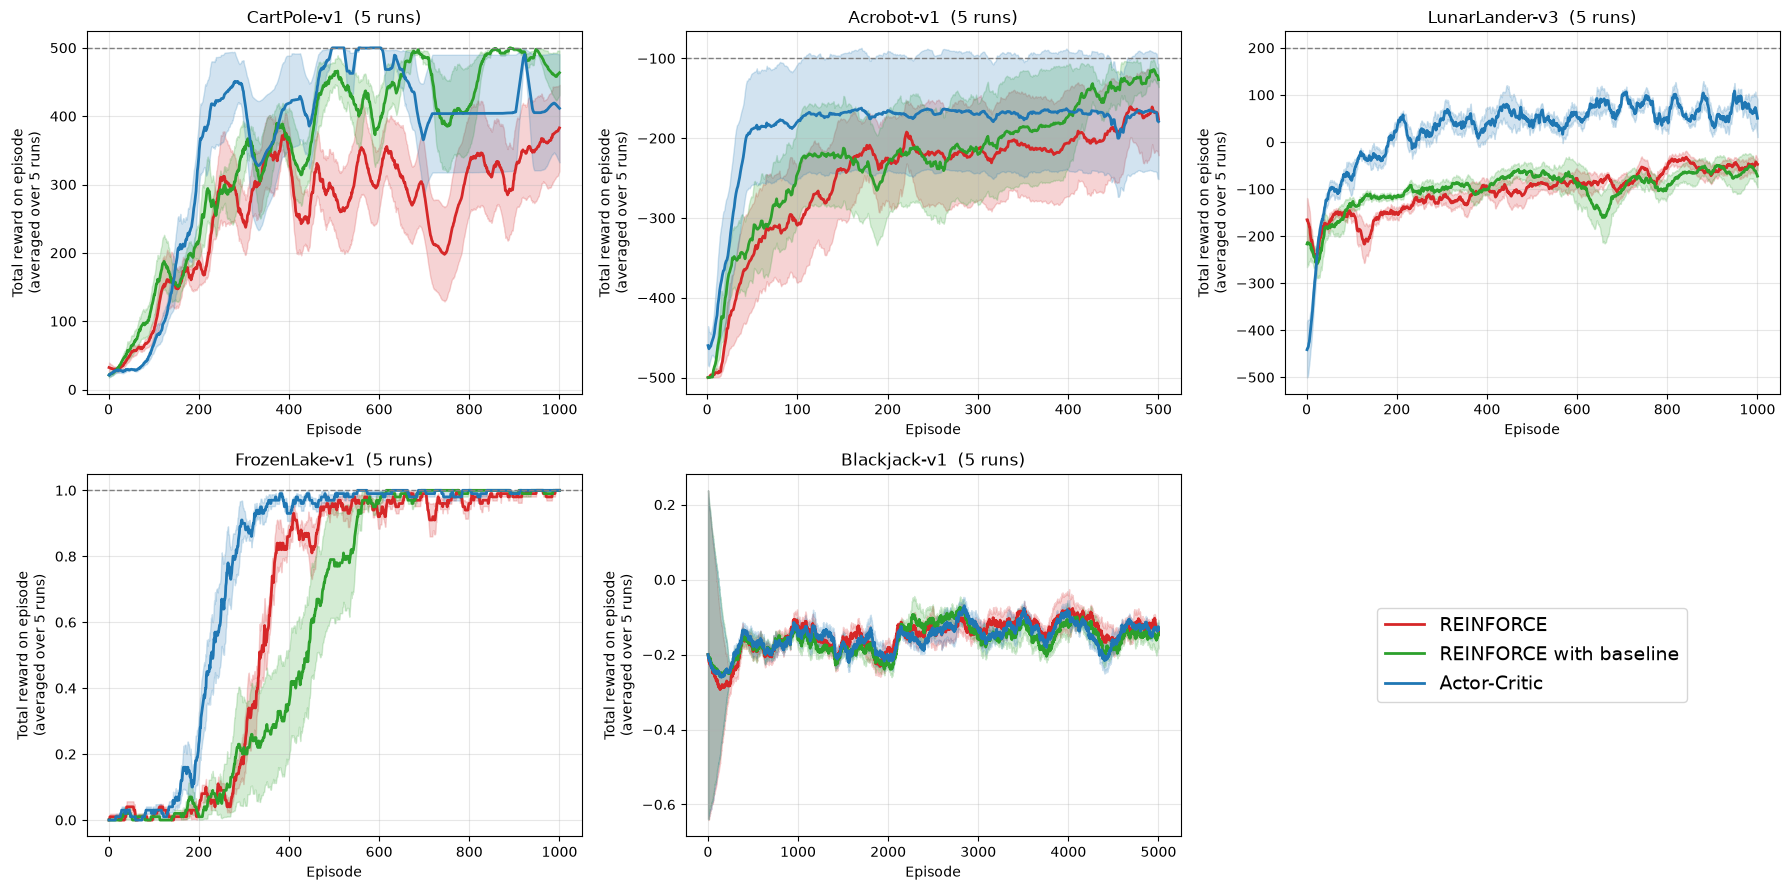

environment                       REINFORCE    REINFORCE with baseline               Actor-Critic
                  mean of last 10% episodes  mean of last 10% episodes  mean of last 10% episodes
CartPole-v1                  362.20 ± 58.19             479.07 ± 16.24             425.81 ± 66.25
Acrobot-v1                  -172.45 ± 49.03            -126.66 ± 16.86            -174.88 ± 72.89
LunarLander-v3               -51.76 ± 12.02             -63.76 ± 27.41              67.23 ± 15.31
FrozenLake-v1                  0.99 ±  0.00               1.00 ±  0.00               1.00 ±  0.00
Blackjack-v1                  -0.13 ±  0.02              -0.15 ±  0.03              -0.13 ±  0.01


In [18]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, env in zip(axes.flat, CONFIGS):
    plot_env(ax, env, RES[env])
axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", fontsize=14)
plt.tight_layout()
plt.show()

print(f"{'environment':16s} " + " ".join(f"{a:>26s}" for a in ALGORITHMS))
print(f"{'':16s} " + " ".join(f"{'mean of last 10% episodes':>26s}" for _ in ALGORITHMS))
for env in CONFIGS:
    by_alg = RES[env]
    n =next(iter(by_alg.values())).shape[1] // 10
    print(f"{env:16s} " + " ".join(f"{by_alg[a][:, -n:].mean():>18.2f} ± {by_alg[a][:, -n:].mean(1).std() / np.sqrt(len(by_alg[a])):5.2f}"
                                    for a in ALGORITHMS))

## 8. Discussion

(The numbers quoted below refer to the summary table above: mean total reward over the last 10% of episodes, ± standard error over runs. The per-run lines in the training log show which runs succeeded or failed.)

**Baseline vs. no baseline.** Subtracting $\hat v(S_t,\mathbf w)$ leaves the expected gradient unchanged but lowers its variance. This shows most clearly on **CartPole** and **Acrobot**. On both, REINFORCE with baseline ends higher than plain REINFORCE (CartPole ≈ 479 vs. 362; Acrobot ≈ −127 vs. −172), and its runs agree with each other much more (smaller band), as S&B Figure 13.2 predicts. Plain REINFORCE on CartPole keeps climbing and then falling back, because single high-variance updates undo progress. On Acrobot one plain-REINFORCE run stays near −400. Every step there gives −1, so without a baseline every update lowers the probability of whatever was done. The baseline makes the signal *relative* ("better or worse than usual from this state"), so good episodes are actually reinforced.

**Actor-Critic.** Bootstrapping from $\hat v(S')$ replaces the full Monte-Carlo return with a one-step TD target. This target is biased while the critic is still wrong, but its variance is much lower, and the agent learns online after every step instead of waiting for the episode to end. This makes it the fastest learner early on, on every environment where learning happens:
* On **Acrobot**, four of five runs reach −80 to −115 (around the solved level of −100) within ~100 episodes.
* On **CartPole**, it is the first method to reach 500.
* On **FrozenLake**, it reaches the goal reliably about 150 episodes before the other two.
* On **LunarLander**, it is the only method that gets clearly above 0 (≈ +67, vs. ≈ −50 to −65 for the Monte-Carlo methods), though still well below the solved level of 200 after 1000 episodes.

The price is **stability**. In one Acrobot run and one CartPole run, the policy collapsed to a near-deterministic bad policy. The critic's errors feed straight back into the actor, and once the policy stops exploring, the critic only sees one kind of trajectory, so the run cannot recover. These single failed runs pull the Actor-Critic average on CartPole (≈ 426) and Acrobot (≈ −175) below REINFORCE with baseline and widen its band. Actor-Critic was also the most sensitive to the step size. With $\alpha_\theta = 3\cdot10^{-4}$ on CartPole, collapses were more frequent, so we used $10^{-4}$.

**FrozenLake (4×4, deterministic).** The reward is sparse (+1 only at the goal), so every method first has to find the goal by chance. After that, all three converge to the optimal policy (return 1). Actor-Critic gets there first because the critic carries the goal's value back to earlier states one step at a time.

**Blackjack.** Episodes last 1–3 steps and the outcome is mostly luck, so the three methods are almost the same here (around −0.13 per hand, versus ≈ −0.04 for the optimal strategy in S&B Example 5.3). All of them improve within the first few hundred hands and then stay roughly flat. With such short episodes, $G_t$ is already a low-variance target, so a baseline or bootstrapping has little to add.

**Implementation notes.**
1. Because of the $\gamma^t$ (or $I$) factor from the episodic policy-gradient theorem, late time steps in long episodes get very small updates. With $\gamma = 0.99$ and 500-step CartPole episodes, the last steps barely contribute.
2. We used Adam for every algorithm. Its per-parameter normalisation made one set of step sizes work across very different reward scales (±1 in Blackjack, ±hundreds in LunarLander), which plain SGD would not.
3. Five runs per curve is much less than S&B's 100. A single failed run moves the mean a lot, so the shaded standard-error bands, and the per-run log, are an important part of reading these plots.
